# 04 — Signal Engineering & Full Feature Panel

**Goal:** Assemble the complete research panel by joining price features, hurricane risk signals, and climate indices. Perform feature selection analysis (IC ranking, redundancy check) and save the final modeling dataset.

**Panel structure:** one row per date × ticker. Each row carries:
- Price features: returns, momentum, volatility, drawdown, skewness (from notebook 01)
- Hurricane features: risk score, gulf disruption proxy, OHC-weighted risk, lags (notebook 03)
- Climate indices: AMO, ONI, PDO daily forward-filled (notebook 03)
- ERA5 weather: temperature anomaly, precipitation anomaly, drought proxy (notebook 02 — merged when available)
- Targets: future returns at 1d / 5d / 10d / 20d horizons

The `region` mapping connects each ticker to its relevant geographic features.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from pathlib import Path

from src.config import DATA_PROCESSED_DIR, DATA_RAW_DIR
from src.data.load_era5 import load_all_era5_regions, nc_to_daily_dataframe
from src.features.weather_features import add_weather_anomalies, add_rolling_weather_features

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# Ticker → primary region mapping (used to attach geographic features)
TICKER_REGION = {
    "UNG":  "gulf_of_mexico",
    "USO":  "gulf_of_mexico",
    "CORN": "us_corn_belt",
    "SOYB": "us_corn_belt",
    "DBA":  "us_corn_belt",
    "WEAT": "us_wheat_plains",
    "GLD":  "gulf_of_mexico",   # control — no climate edge expected
}

## 1. Load all processed datasets

In [2]:
prices = pd.read_parquet(DATA_PROCESSED_DIR / "signal_dataset.parquet")
prices["date"] = pd.to_datetime(prices["date"])

hurr = pd.read_parquet(DATA_PROCESSED_DIR / "hurricane_features.parquet")
hurr["date"] = pd.to_datetime(hurr["date"])

ci = pd.read_parquet(DATA_PROCESSED_DIR / "climate_indices_daily.parquet")
ci["date"] = pd.to_datetime(ci["date"])

# ERA5 surface — load whatever is available; fill gaps with NaN
era5_dir = DATA_RAW_DIR / "weather" / "era5"
era5_files = sorted(era5_dir.glob("era5_*.nc"))
print(f"ERA5 files available: {len(era5_files)}/84")

if era5_files:
    era5_raw = load_all_era5_regions(nc_dir=era5_dir)
    era5_raw["date"] = pd.to_datetime(era5_raw["date"])
    era5_feat = add_weather_anomalies(era5_raw, group_cols=["region"])
    era5_feat = add_rolling_weather_features(era5_feat)
    print(f"ERA5 panel: {era5_feat.shape} | years: "
          f"{era5_feat['date'].dt.year.min()}–{era5_feat['date'].dt.year.max()}")
else:
    era5_feat = None
    print("ERA5 not yet available — panel will be built without weather features.")

ERA5 files available: 84/84


ERA5 panel: (30680, 21) | years: 2005–2025


## 2. Assemble the full signal panel

In [3]:
HURR_COLS = [
    "hurricane_risk_score", "min_storm_distance_km", "max_storm_wind_kt",
    "hurricane_active", "gulf_disruption_proxy", "ohc_weighted_risk",
    "storm_active_7d", "hurricane_risk_lag1d", "hurricane_risk_lag3d",
    "hurricane_risk_lag5d",
]
ERA5_COLS = [
    "temperature_anomaly", "precipitation_anomaly",
    "temp_anomaly_7d", "temp_anomaly_30d",
    "precip_anomaly_7d", "precip_anomaly_30d",
    "drought_proxy_60d", "extreme_weather_flag",
]

rows = []
for ticker, region in TICKER_REGION.items():
    sub = prices[prices["ticker"] == ticker].copy()

    # -- Hurricane features (region-specific) --
    hdf = hurr[hurr["region"] == region][["date"] + [c for c in HURR_COLS if c in hurr.columns]]
    hdf = (hdf.set_index("date")
              .reindex(sub["date"].values, method="ffill")
              .reset_index().rename(columns={"index": "date"}))
    sub = sub.merge(hdf, on="date", how="left")

    # -- Climate indices (global, same for all tickers) --
    sub = sub.merge(ci, on="date", how="left")

    # -- ERA5 surface (region-specific, partial coverage) --
    if era5_feat is not None:
        edf = era5_feat[era5_feat["region"] == region]
        avail_era5 = [c for c in ERA5_COLS if c in edf.columns]
        if avail_era5:
            edf = (edf[["date"] + avail_era5]
                   .set_index("date")
                   .reindex(sub["date"].values, method="ffill")
                   .reset_index().rename(columns={"index": "date"}))
            sub = sub.merge(edf, on="date", how="left")

    sub["region"] = region
    rows.append(sub)

panel = pd.concat(rows, ignore_index=True).sort_values(["ticker", "date"])

print(f"Full panel: {panel.shape[0]:,} rows × {panel.shape[1]} columns")
print(f"Tickers: {sorted(panel['ticker'].unique())}")
print(f"Date range: {panel['date'].min().date()} → {panel['date'].max().date()}")
panel.head(3)

Full panel: 31,430 rows × 46 columns
Tickers: ['CORN', 'DBA', 'GLD', 'SOYB', 'UNG', 'USO', 'WEAT']
Date range: 2005-01-03 → 2026-05-05


,date,ticker,close,asset,return_1d,return_5d,return_20d,volatility_20d,volatility_60d,momentum_20d,...,pdo,temperature_anomaly,precipitation_anomaly,temp_anomaly_7d,temp_anomaly_30d,precip_anomaly_7d,precip_anomaly_30d,drought_proxy_60d,extreme_weather_flag,region
9842,2010-06-09,CORN,25.150000,corn,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.79,-0.309195,0.336187,-0.210067,0.727474,0.802800,1.200338,0.235836,1,us_corn_belt
9843,2010-06-10,CORN,25.459999,corn,0.012326,NaN,NaN,NaN,NaN,NaN,...,-0.79,-0.063351,-0.034247,-0.197354,0.871712,0.752244,0.740036,0.368681,0,us_corn_belt
9844,2010-06-11,CORN,25.790001,corn,0.012962,NaN,NaN,NaN,NaN,NaN,...,-0.79,1.156820,0.207194,-0.208726,1.000264,0.919429,0.823401,0.701391,0,us_corn_belt


## 3. Missing value audit

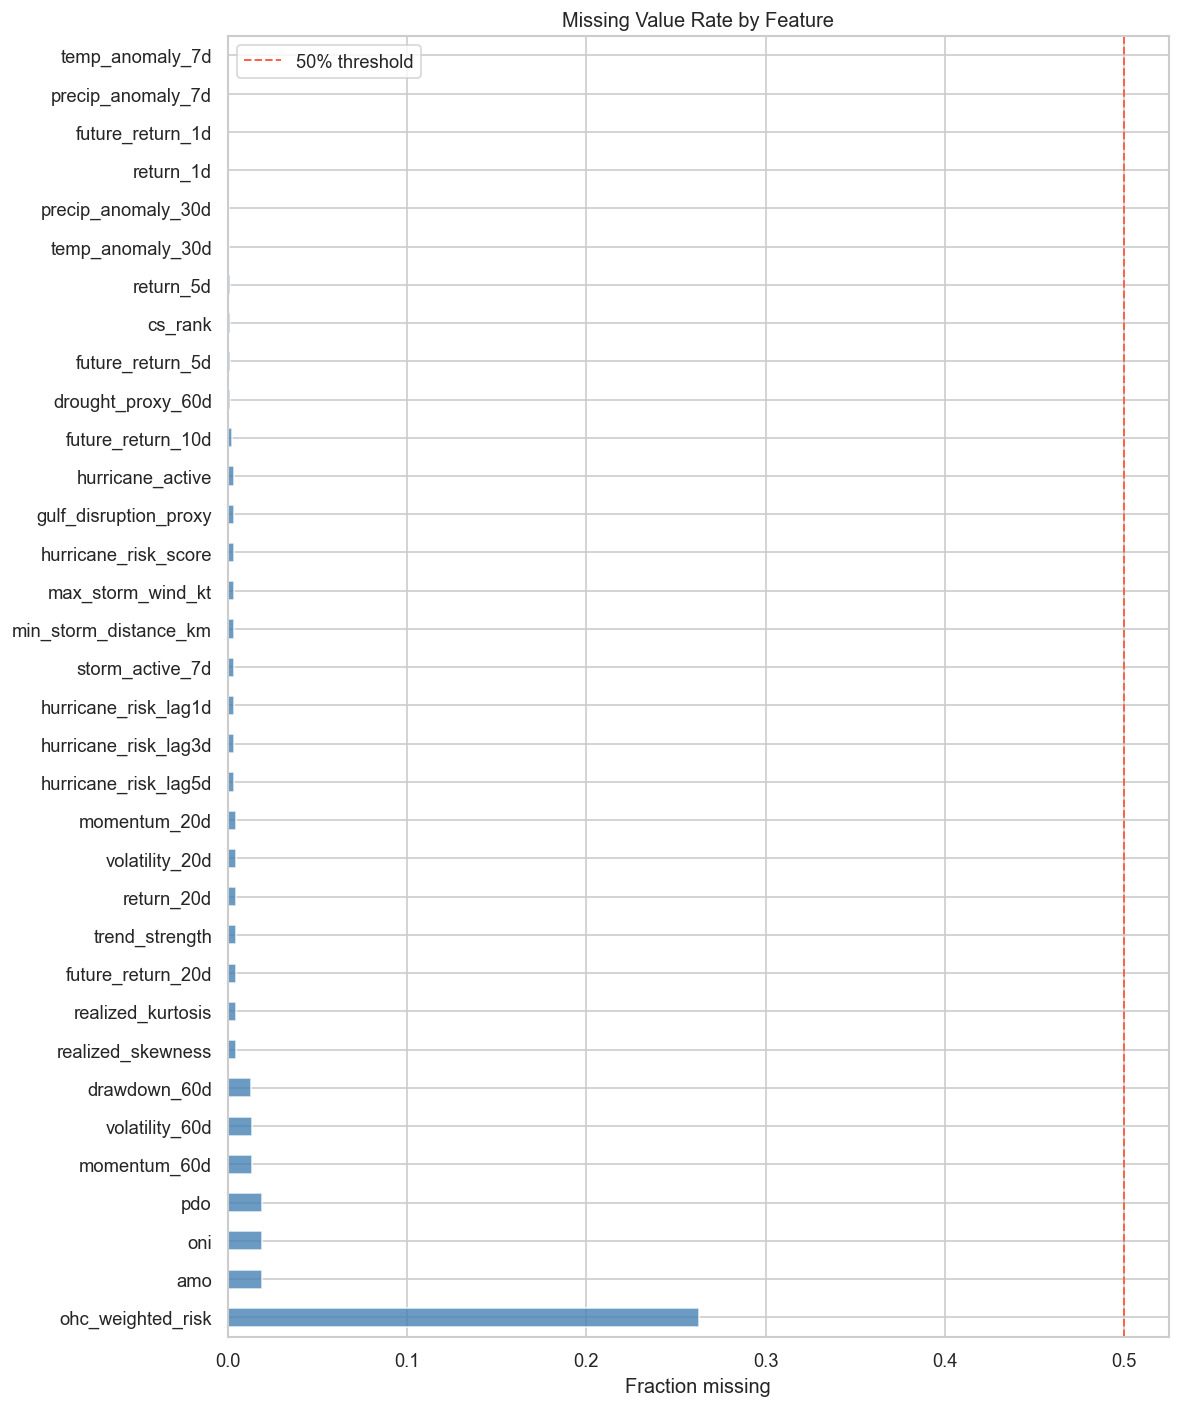


Features > 30% missing:
Series([], )


In [4]:
missing = panel.isnull().mean().sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(10, max(3, len(missing) * 0.35)))
missing.plot.barh(ax=ax, color="steelblue", alpha=0.8)
ax.axvline(0.5, color="tomato", lw=1.2, ls="--", label="50% threshold")
ax.set_xlabel("Fraction missing")
ax.set_title("Missing Value Rate by Feature")
ax.legend()
plt.tight_layout()
plt.show()

print("\nFeatures > 30% missing:")
print(missing[missing > 0.3].to_string())

## 4. IC ranking — all features vs 5d forward return

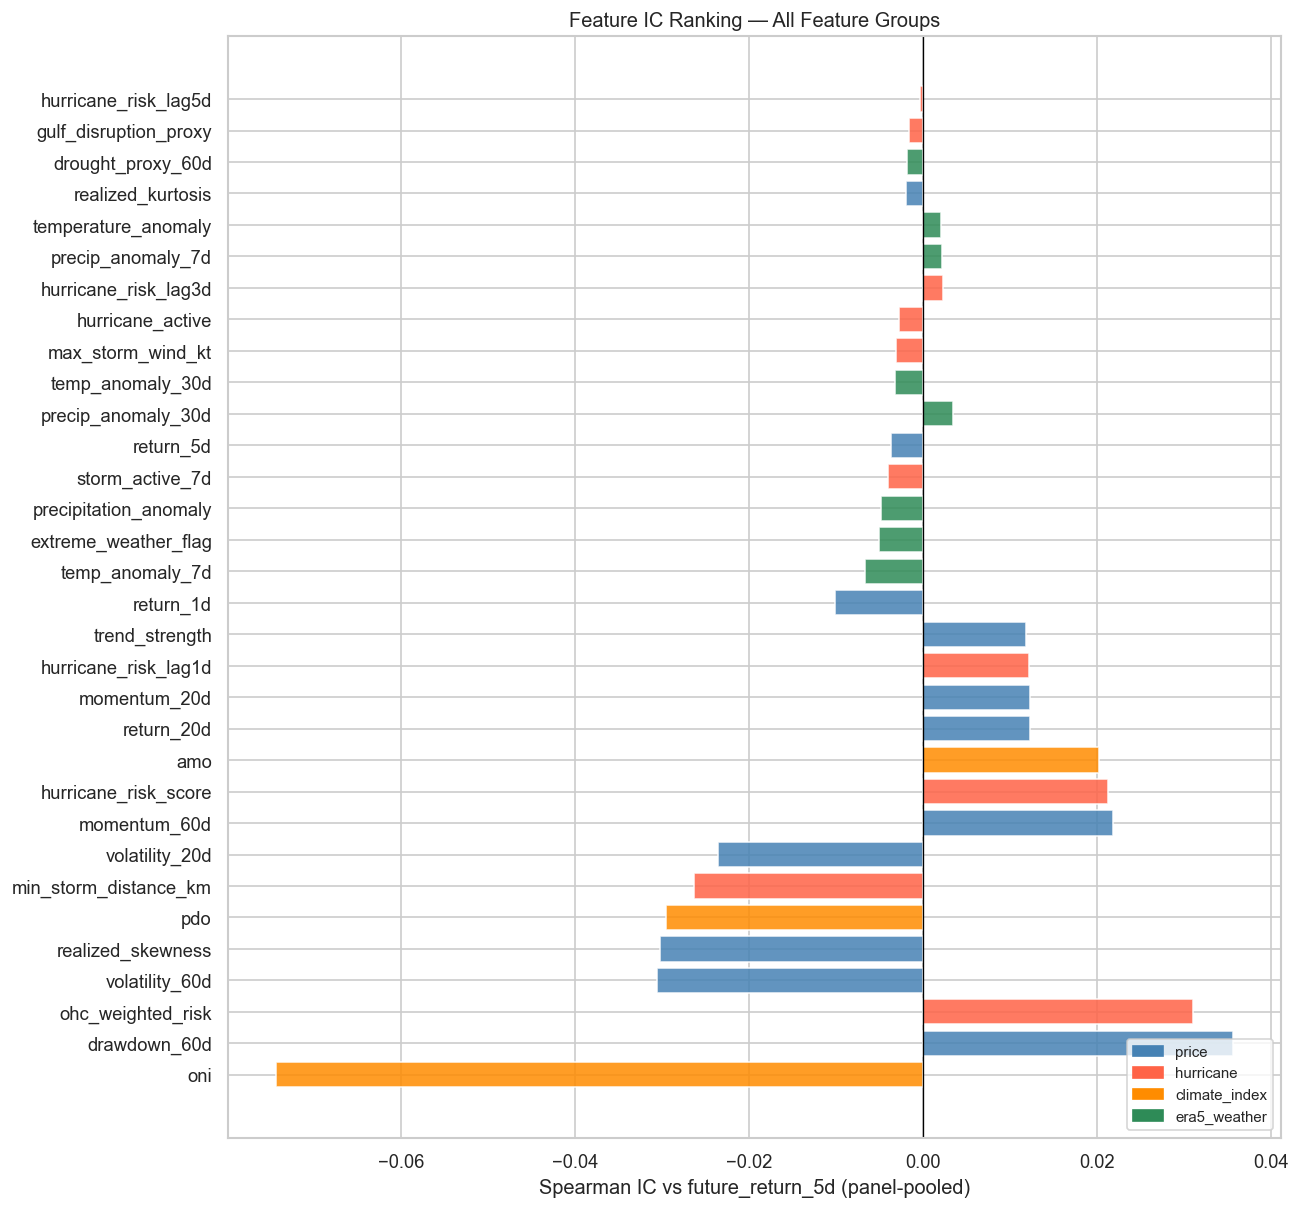

,feature,IC,abs_IC,pval,n,group
22,oni,-0.074436,0.074436,3.831582e-39,30835,climate_index
7,drawdown_60d,0.035636,0.035636,3.512605e-10,30982,price
16,ohc_weighted_risk,0.031022,0.031022,2.373713e-06,23128,hurricane
4,volatility_60d,-0.030605,0.030605,7.146616e-08,30975,price
9,realized_skewness,-0.030292,0.030292,8.490644e-08,31255,price
23,pdo,-0.029518,0.029518,2.167978e-07,30835,climate_index
12,min_storm_distance_km,-0.026349,0.026349,3.142049e-06,31287,hurricane
3,volatility_20d,-0.023598,0.023598,3.014911e-05,31255,price
6,momentum_60d,0.021882,0.021882,1.174492e-04,30975,price
11,hurricane_risk_score,0.021328,0.021328,1.614680e-04,31287,hurricane


In [5]:
TARGET = "future_return_5d"

PRICE_FEATURES = [
    "return_1d", "return_5d", "return_20d",
    "volatility_20d", "volatility_60d",
    "momentum_20d", "momentum_60d",
    "drawdown_60d", "trend_strength",
    "realized_skewness", "realized_kurtosis",
]
HURR_FEATURES = [c for c in HURR_COLS if c in panel.columns]
CI_FEATURES   = ["amo", "oni", "pdo"]
ERA5_FEATURES = [c for c in ERA5_COLS if c in panel.columns]

ALL_FEATURES  = PRICE_FEATURES + HURR_FEATURES + CI_FEATURES + ERA5_FEATURES

ic_rows = []
for feat in ALL_FEATURES:
    if feat not in panel.columns:
        continue
    valid = panel[[feat, TARGET]].dropna()
    if len(valid) < 100:
        continue
    rho, pval = spearmanr(valid[feat], valid[TARGET])
    group = ("price" if feat in PRICE_FEATURES
             else "hurricane" if feat in HURR_FEATURES
             else "climate_index" if feat in CI_FEATURES
             else "era5_weather")
    ic_rows.append({"feature": feat, "IC": rho, "abs_IC": abs(rho),
                    "pval": pval, "n": len(valid), "group": group})

ic_all = pd.DataFrame(ic_rows).sort_values("abs_IC", ascending=False)

# Color map by group
colors = {"price": "steelblue", "hurricane": "tomato",
          "climate_index": "darkorange", "era5_weather": "seagreen"}

fig, ax = plt.subplots(figsize=(11, max(4, len(ic_all) * 0.32)))
bar_colors = [colors[g] for g in ic_all["group"]]
ax.barh(ic_all["feature"], ic_all["IC"], color=bar_colors, alpha=0.85)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman IC vs future_return_5d (panel-pooled)")
ax.set_title("Feature IC Ranking — All Feature Groups")

patches = [mpatches.Patch(color=c, label=g) for g, c in colors.items()]
ax.legend(handles=patches, fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=150)
plt.show()

ic_all.head(20)

## 5. Feature correlation matrix — redundancy check

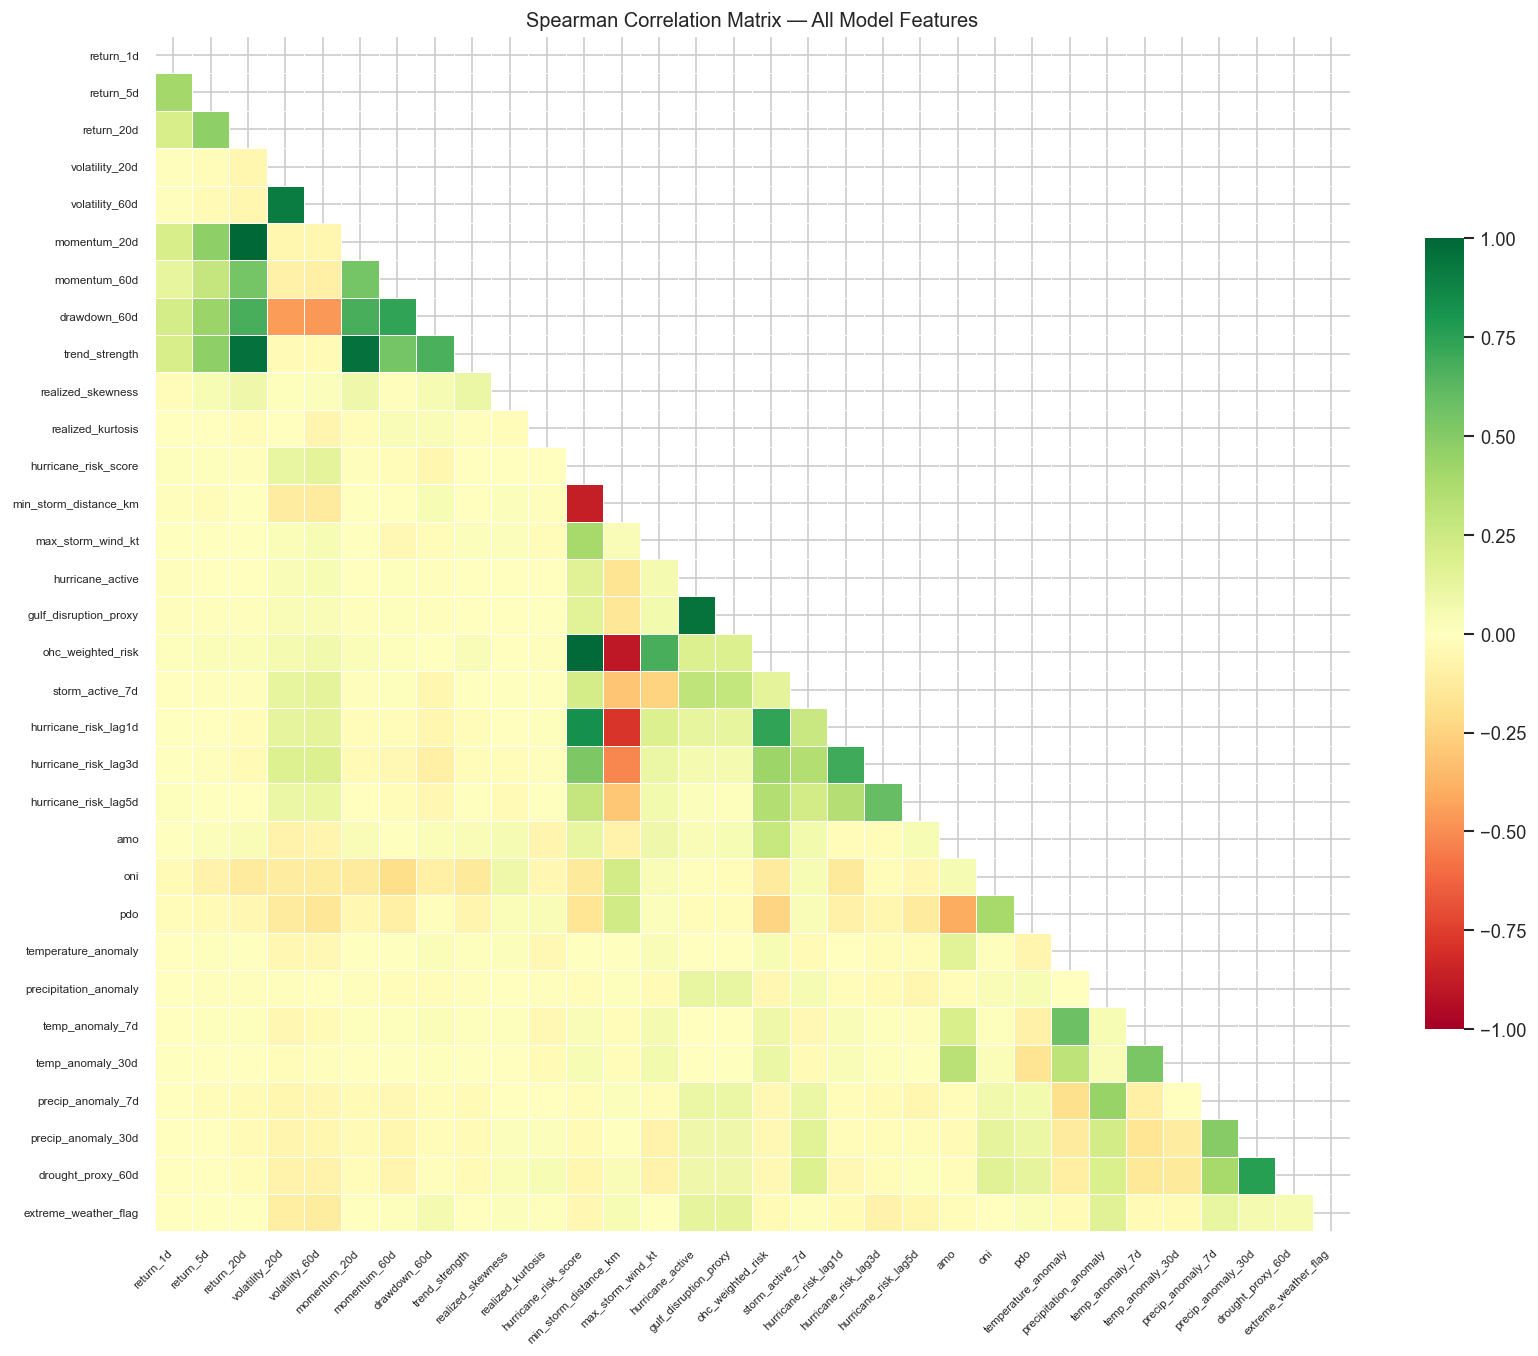

High-correlation pairs (|r| > 0.8):
               feat_a                feat_b   corr
           return_20d          momentum_20d  1.000
 hurricane_risk_score     ohc_weighted_risk  0.987
           return_20d        trend_strength  0.958
         momentum_20d        trend_strength  0.958
     hurricane_active gulf_disruption_proxy  0.949
       volatility_20d        volatility_60d  0.922
min_storm_distance_km     ohc_weighted_risk -0.893
 hurricane_risk_score min_storm_distance_km -0.872
 hurricane_risk_score  hurricane_risk_lag1d  0.825


In [6]:
model_features = [f for f in ALL_FEATURES if f in panel.columns
                  and panel[f].isnull().mean() < 0.6]

corr = panel[model_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdYlGn", center=0, vmin=-1, vmax=1,
            ax=ax, linewidths=0.3, square=True,
            xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": 0.6})
ax.set_title("Spearman Correlation Matrix — All Model Features", fontsize=12)
plt.xticks(fontsize=7, rotation=45, ha="right")
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

# Pairs with |corr| > 0.8 (potential redundancy)
high_corr = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        v = corr.iloc[i, j]
        if abs(v) > 0.8:
            high_corr.append({"feat_a": corr.columns[i],
                               "feat_b": corr.columns[j], "corr": round(v, 3)})
if high_corr:
    print("High-correlation pairs (|r| > 0.8):")
    print(pd.DataFrame(high_corr).sort_values("corr", key=abs, ascending=False).to_string(index=False))
else:
    print("No pairs with |corr| > 0.8")

## 6. Define final feature sets for modeling

In [7]:
# Baseline: price features only (the benchmark models in notebook 05 must beat this)
FEATURES_PRICE = [f for f in PRICE_FEATURES if f in panel.columns]

# Full: price + hurricane + climate indices (always available)
FEATURES_FULL = [f for f in PRICE_FEATURES + HURR_FEATURES + CI_FEATURES
                 if f in panel.columns and panel[f].isnull().mean() < 0.6]

# Full + ERA5 (available for years/regions with downloaded data)
FEATURES_FULL_ERA5 = [f for f in FEATURES_FULL + ERA5_FEATURES
                      if f in panel.columns and panel[f].isnull().mean() < 0.6]

print(f"FEATURES_PRICE   : {len(FEATURES_PRICE)} features")
print(f"FEATURES_FULL    : {len(FEATURES_FULL)} features")
print(f"FEATURES_FULL_ERA5: {len(FEATURES_FULL_ERA5)} features")
print()
print("Full feature list:")
for f in FEATURES_FULL:
    group = ("price" if f in PRICE_FEATURES
             else "hurricane" if f in HURR_FEATURES
             else "climate_index")
    pct_miss = panel[f].isnull().mean()
    ic_row = ic_all[ic_all["feature"] == f]
    ic_val = ic_row["IC"].values[0] if len(ic_row) else float("nan")
    print(f"  {f:<35} [{group:<14}]  IC={ic_val:+.4f}  missing={pct_miss:.1%}")

FEATURES_PRICE   : 11 features
FEATURES_FULL    : 24 features
FEATURES_FULL_ERA5: 32 features

Full feature list:
  return_1d                           [price         ]  IC=-0.0101  missing=0.0%
  return_5d                           [price         ]  IC=-0.0037  missing=0.1%
  return_20d                          [price         ]  IC=+0.0123  missing=0.4%
  volatility_20d                      [price         ]  IC=-0.0236  missing=0.4%
  volatility_60d                      [price         ]  IC=-0.0306  missing=1.3%
  momentum_20d                        [price         ]  IC=+0.0123  missing=0.4%
  momentum_60d                        [price         ]  IC=+0.0219  missing=1.3%
  drawdown_60d                        [price         ]  IC=+0.0356  missing=1.3%
  trend_strength                      [price         ]  IC=+0.0119  missing=0.4%
  realized_skewness                   [price         ]  IC=-0.0303  missing=0.4%
  realized_kurtosis                   [price         ]  IC=-0.0019  missing=

## 7. Save final modeling dataset

In [8]:
import json

panel.to_parquet(DATA_PROCESSED_DIR / "modeling_panel.parquet", index=False)

# Save feature set definitions for reproducibility
feature_sets = {
    "FEATURES_PRICE":    FEATURES_PRICE,
    "FEATURES_FULL":     FEATURES_FULL,
    "FEATURES_FULL_ERA5": FEATURES_FULL_ERA5,
    "TARGET":            TARGET,
    "TICKER_REGION":     TICKER_REGION,
}
with open(DATA_PROCESSED_DIR / "feature_sets.json", "w") as fh:
    json.dump(feature_sets, fh, indent=2)

print(f"modeling_panel.parquet  — {panel.shape[0]:,} rows × {panel.shape[1]} cols")
print(f"feature_sets.json       — {len(FEATURES_FULL)} features in FEATURES_FULL")

# Quick sanity: rows with complete FEATURES_FULL
complete = panel[FEATURES_FULL + [TARGET]].dropna()
print(f"\nRows with complete FEATURES_FULL + target: {len(complete):,} "
      f"({len(complete)/len(panel):.1%} of panel)")

modeling_panel.parquet  — 31,430 rows × 46 cols
feature_sets.json       — 24 features in FEATURES_FULL

Rows with complete FEATURES_FULL + target: 22,288 (70.9% of panel)
